In [1]:
from pathlib import Path
import numpy as np
import numpy.ma as ma
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy import stats

In [2]:
# Constant values

Er = 0.65 # activation energy in eV
k = 8.6173303e-5 # Boltzmann constant in eV/K

DATA_DIR = Path('C:/Users/reva4589/Documents/CALIPSO/DATA/')
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)

N_BOOT      = 10000   # bootstrap resamples for all main fits
N_BOOT_SENS = 2000    # resamples per E_r value in the sensitivity sweep
CI_LEVEL    = 95.0
SEED        = 1201

plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
})

In [3]:
### Hu et al. 2025

he_data = pd.read_csv(DATA_DIR/'xianjin_data.csv')
print(he_data.columns)
he_data = he_data[he_data["pH"].between(3.8, 8.0)]

rh_he = he_data['Respiration'].to_numpy() # mg C /kg/hr
growth_he = he_data['Growth'].to_numpy() # mg C /kg/hr
soc_he = he_data['SOC'].to_numpy() # g/kg
mbc_he = he_data['MBC'].to_numpy() # mg C /kg
incT_he = he_data['Inc. Temp.'].to_numpy() # Celsius

# Unit conversion
rh_he = rh_he * 1e-3 # g/kg/hr
growth_he = growth_he * 1e-3 # g/kg/hr
mbc_he = mbc_he * 1e-3 # g/kg
incT_he = incT_he + 273.15 # K

# masking nan values
rh_he = ma.masked_invalid(rh_he)
growth_he = ma.masked_invalid(growth_he)
soc_he = ma.masked_invalid(soc_he)
mbc_he = ma.masked_invalid(mbc_he)
incT_he = ma.masked_invalid(incT_he)
uptake_he = rh_he + growth_he

# temperature correction rates
rh_T_he = rh_he * np.exp(Er/(k*incT_he))
growth_T_he = growth_he * np.exp(Er/(k*incT_he))
uptake_T_he = uptake_he * np.exp(Er/(k*incT_he))

Index(['No.', 'latitude', 'longitude', 'Biome', 'MAP', 'MAT', 'SOC', 'TN',
       'TP', 'MBC', 'MBN', 'Growth', 'Respiration', 'CUE', 'Soil depth',
       'Inc. Temp.', 'Inc. Time', 'Inc. WHC', 'Data source', 'doi', 'pH'],
      dtype='object')


In [4]:
### Cruz-Paredes et al. 2023

brangari_data = pd.read_csv(DATA_DIR/'brangari_csv.csv')
print(brangari_data.columns)

rh_brangari = brangari_data['respiration (mgC/kg soil/h)'].to_numpy() # mg C /kg/hr
growth_brangari = brangari_data['total growth (mgC/kg soil/h)'].to_numpy() # mg C /kg/hr
uptake_brangari = brangari_data['uptake (mgC/kg soil/h)'].to_numpy() # mg C /kg/hr
soc_brangari = brangari_data['soil organic matter (%)'].to_numpy() # % SOM

# Unit conversion
rh_brangari = rh_brangari * 1e-3 # g/kg/h
growth_brangari = growth_brangari * 1e-3 # g/kg/h
uptake_brangari = uptake_brangari * 1e-3 # g/kg/h
soc_brangari = (soc_brangari * 10)/2 # convert % SOM to g/kg SOC (approximately 2)

# masking nan values
rh_brangari = ma.masked_invalid(rh_brangari)
growth_brangari = ma.masked_invalid(growth_brangari)
uptake_brangari = ma.masked_invalid(uptake_brangari)
soc_brangari = ma.masked_invalid(soc_brangari)

# mineral soils only (SOC > 200 g/kg)
rh_brangari = ma.masked_where(soc_brangari > 200, rh_brangari)
growth_brangari = ma.masked_where(soc_brangari > 200, growth_brangari)
uptake_brangari = ma.masked_where(soc_brangari > 200, uptake_brangari)
soc_brangari = ma.masked_where(soc_brangari > 200, soc_brangari)

# temperature correction rates
rh_T_brangari = rh_brangari * np.exp(Er/(k*293.15)) # 20C incubation T
growth_T_brangari = growth_brangari * np.exp(Er/(k*293.15)) # 20C incubation T
uptake_T_brangari = uptake_brangari * np.exp(Er/(k*293.15)) # 20C incubation T

Index(['soil ID', 'soil organic matter (%)',
       'mean annual temperature (degree C)', 'coefficient (ugC/g soil/h)',
       'activation energy (eV)', 'activation energy (degree K)',
       'bacterial growth (mgC/kg soil/h)', 'fungal growth (mgC/kg soil/h)',
       'total growth (mgC/kg soil/h)', 'respiration (mgC/kg soil/h)',
       'uptake (mgC/kg soil/h)'],
      dtype='object')


In [5]:
### LUCAS dataset

lucas_data1 = pd.read_csv(DATA_DIR/'LUCAS/lucas_soc.csv')
lucas_data2 = pd.read_csv(DATA_DIR/'LUCAS/lucas_mbc_rh.csv')

lucas_data = pd.merge(lucas_data1, lucas_data2, on='LUCAS_ID', how='inner')
num = ['Basal_respiration', 'Cmic']
lucas_data[num] = lucas_data.groupby('LUCAS_ID')[num].transform('mean')
lucas_data = lucas_data.drop_duplicates('LUCAS_ID')
print(lucas_data.columns)

lucas_data_filtered = lucas_data[lucas_data["pH_H2O"].between(3.8, 8.0)]
lucas_data_filtered = lucas_data_filtered[lucas_data_filtered["pH_CaCl2"].between(3.8, 8.0)]
lucas_data_filtered = lucas_data_filtered[~lucas_data_filtered["LC0_Desc"].isin(["Wetlands", "Water", "Artificial land"])]

rh_lucas = lucas_data_filtered['Basal_respiration'].to_numpy() # μl O2 h-1 g soil dw-1
mbc_lucas = lucas_data_filtered['Cmic'].to_numpy() # µg Cmic g soil dw-1
soc_lucas = lucas_data_filtered['OC'].to_numpy() # g/kg
soc_lucas = pd.to_numeric(soc_lucas, errors='coerce')

# Unit conversion
rh_lucas = rh_lucas * (1/24.0551e6) * 1 * 12.01 * 1e3 # g/kg/h
mbc_lucas = mbc_lucas * 1e-3 # g/kg

# masking nan values
rh_lucas = ma.masked_invalid(rh_lucas)
mbc_lucas = ma.masked_invalid(mbc_lucas)
soc_lucas = ma.masked_invalid(soc_lucas)

# mineral soils only (SOC > 200 g/kg)
rh_lucas = ma.masked_where(rh_lucas == 0, rh_lucas)
rh_lucas = ma.masked_where(soc_lucas > 200, rh_lucas)
mbc_lucas = ma.masked_where(soc_lucas > 200, mbc_lucas)
soc_lucas = ma.masked_where(soc_lucas > 200, soc_lucas)

# temperature correction rates
rh_T_lucas = rh_lucas * np.exp(Er/(k*293.15)) # 20C incubation T

Index(['Depth', 'LUCAS_ID', 'pH_CaCl2', 'pH_H2O', 'EC', 'OC', 'CaCO3', 'P',
       'N', 'K', 'OC (20-30 cm)', 'CaCO3 (20-30 cm)', 'Ox_Al', 'Ox_Fe',
       'NUTS_0', 'NUTS_1', 'NUTS_2', 'NUTS_3', 'TH_LAT', 'TH_LONG',
       'SURVEY_DATE', 'Elev', 'LC', 'LU', 'LC0_Desc', 'LC1_Desc', 'LU1_Desc',
       'WHC', 'Mean_width_diameter', 'Water_stable_aggregates', 'Xylosidase',
       'Cellulase', 'N_actylglucosaminidase', 'Beta_glucosidase',
       'Acid_phosphatase', 'Basal_respiration', 'MIRR', 'Cmic', 'qO2',
       'FAME_Gram_positive', 'FAME_Gram_negative', 'FAME_Fungi',
       'FAME_Bacteria', 'FAME_Saturated', 'FAME_Monosaturated',
       'FAME_Actinobacteria', 'FAME_Total', 'FAME_ratio_Gram_pos_neg',
       'FAME_ratio_Fungi_Bacteria', 'FAME_ratio_Sat_Monosat'],
      dtype='object')


In [6]:
def rma_regression_with_bootstrap(x, y, n_boot: int = 2000, ci: float = 95.0, random_state: int | None = None):
    """
    Perform RMA (Reduced Major Axis) regression between x and y with bootstrap CI.

    Parameters
    ----------
    x, y : numpy.ma.MaskedArray
        Input masked arrays.
    n_boot : int
        Number of bootstrap resamples to estimate uncertainty (default 2000).
    ci : float
        Confidence interval percentage (e.g. 95).
    random_state : int or None
        Seed for reproducible bootstrapping.

    """

    rng = np.random.default_rng(random_state)

    if x.shape != y.shape:
        raise ValueError("x and y must have the same shape.")

    valid = ~(np.ma.getmaskarray(x) | np.ma.getmaskarray(y))
    x_valid = x.data[valid]
    y_valid = y.data[valid]
    n = x_valid.size
    if n < 2:
        raise ValueError("Need at least two paired, unmasked observations to fit RMA.")

    xm = x_valid.mean()
    ym = y_valid.mean()
    sx = np.std(x_valid, ddof=1)
    sy = np.std(y_valid, ddof=1)

    if sx == 0 or sy == 0:
        raise ValueError("Zero variance in x or y among valid paired observations.")

    r = np.corrcoef(x_valid, y_valid)[0, 1]
    if not np.isfinite(r):
        raise ValueError("Correlation is undefined (NaN or Inf) among valid paired observations.")

    # RMA slope formula: slope = sign(r) * (sy / sx)
    slope = np.sign(r) * (sy / sx)
    intercept = ym - slope * xm

    # Bootstrapping paired observations to get slopes distribution
    boot_slopes = np.empty(n_boot, dtype=float)
    boot_intercepts = np.empty(n_boot, dtype=float)

    iterator = range(n_boot)
    for i in iterator:
        # sample indices with replacement from 0...n-1
        idx = rng.integers(0, n, size=n)
        xs = x_valid[idx]
        ys = y_valid[idx]
        # compute sample stats
        xm_b, ym_b = xs.mean(), ys.mean()
        sx_b = np.std(xs, ddof=1)
        sy_b = np.std(ys, ddof=1)

        if sx_b == 0 or sy_b == 0:
            boot_slopes[i] = np.nan
            boot_intercepts[i] = np.nan
            continue

        r_b = np.corrcoef(xs, ys)[0, 1]
        if not np.isfinite(r_b):
            boot_slopes[i] = np.nan
            boot_intercepts[i] = np.nan
            continue
        slope_b = np.sign(r_b) * (sy_b / sx_b)
        intercept_b = ym_b - slope_b * xm_b

        boot_slopes[i] = slope_b
        boot_intercepts[i] = intercept_b

    # Confidence intervals from percentiles
    lower_pct = (100.0 - ci) / 2.0
    upper_pct = 100.0 - lower_pct
    slope_ci = (np.nanpercentile(boot_slopes, lower_pct), np.nanpercentile(boot_slopes, upper_pct))
    intercept_ci = (np.nanpercentile(boot_intercepts, lower_pct), np.nanpercentile(boot_intercepts, upper_pct))

    result = {
        'slope': slope,
        'intercept': intercept,
        'slope_ci': slope_ci,
        'intercept_ci': intercept_ci,
        'x_valid': x_valid,
        'y_valid': y_valid,
        'n_valid': n,
        'boot_slopes': boot_slopes,
        'boot_intercepts': boot_intercepts,
        'ci': ci,
    }

    return result

def bootstrap_slope_test(result, null_slope: float = 1.0):
    """
    Test whether the RMA slope is significantly different from a null value
    (e.g. 1.0 for MTE prediction), using the bootstrap slope distribution.
 
    Parameters
    ----------
    result : dict
        Output of rma_regression_with_bootstrap (must contain 'boot_slopes').
    null_slope : float
        The value to test the slope against (default 1.0).
 
    Returns
    -------
    dict with keys:
        null_slope        : the value tested against
        in_ci             : bool, whether null_slope falls inside slope_ci
        p_value           : two-sided bootstrap p-value
        significant       : bool, p_value < (1 - ci/100)
    """
    
    boot_slopes = result['boot_slopes']
    ci = result['ci']
    alpha = 1.0 - ci / 100.0
 
    lo, hi = result['slope_ci']
    in_ci = lo <= null_slope <= hi
 
    valid_boot = boot_slopes[~np.isnan(boot_slopes)]
    prop_below = np.mean(valid_boot <= null_slope)
    prop_above = np.mean(valid_boot >= null_slope)
    p_value = 2 * min(prop_below, prop_above)
    p_value = min(p_value, 1.0)  # guard against >1 from double-counting at the boundary
 
    return {
        'null_slope': null_slope,
        'in_ci': in_ci,
        'p_value': p_value,
        'significant': p_value < alpha,
    }

def run_sensitivity(x, y_raw, T_inc, parameters):
    """
    Sensitivity analysis for RMA slope with respect to activation energy (Er).
    """
    slopes, ci_lo, ci_hi = [], [], []
    for param in parameters:

        exponent = param / (k * T_inc)
        # Guard against overflow
        safe_exponent = ma.masked_where(exponent > 700, exponent)

        T_corrected = y_raw * ma.exp(safe_exponent)
        lnT_corrected = ma.log(T_corrected)

        res = rma_regression_with_bootstrap(x, lnT_corrected, n_boot=N_BOOT_SENS, ci=95.0, random_state=SEED)
        slopes.append(res['slope'])
        ci_lo.append(res['slope_ci'][0])
        ci_hi.append(res['slope_ci'][1])

    return np.array(slopes), np.array(ci_lo), np.array(ci_hi)

Hu et al. 2025: slope = 1.02 (95% CI: 0.89-1.16), p = 0.7876 n points (Hu et al. 2025): 168
LUCAS: slope = 1.15 (95% CI: 1.07-1.22), p = 0.0000 n points (LUCAS): 587


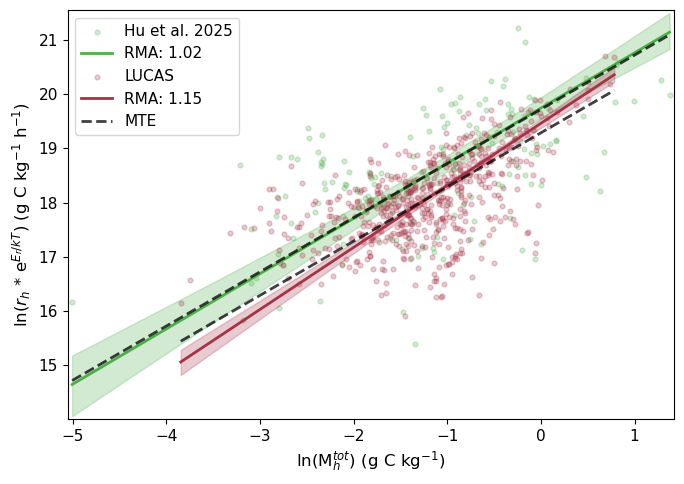

In [7]:
### MBC vs Rh

# He et al. 2026
x_he = ma.log(mbc_he)
y_he = ma.log(rh_T_he)

# LUCAS
x_lucas = ma.log(mbc_lucas)
y_lucas = ma.log(rh_T_lucas)

res_he = rma_regression_with_bootstrap(x_he, y_he, n_boot=N_BOOT, ci=CI_LEVEL, random_state=SEED)
res_lucas = rma_regression_with_bootstrap(x_lucas, y_lucas, n_boot=N_BOOT, ci=CI_LEVEL, random_state=SEED)

test_he = bootstrap_slope_test(res_he, null_slope=1.0)
test_lucas = bootstrap_slope_test(res_lucas, null_slope=1.0)

print(f"Hu et al. 2025: slope = {res_he['slope']:.2f} (95% CI: {res_he['slope_ci'][0]:.2f}-{res_he['slope_ci'][1]:.2f}), p = {test_he['p_value']:.4f}", 'n points (Hu et al. 2025):', res_he["n_valid"])
print(f"LUCAS: slope = {res_lucas['slope']:.2f} (95% CI: {res_lucas['slope_ci'][0]:.2f}-{res_lucas['slope_ci'][1]:.2f}), p = {test_lucas['p_value']:.4f}", 'n points (LUCAS):', res_lucas["n_valid"])

fig, ax = plt.subplots(figsize=(7, 5))
def plot_dataset(ax, res, color, label):
    ax.scatter(res['x_valid'], res['y_valid'], s=12, alpha=0.25, color=color,
               label=f'{label}')

    xline = np.linspace(res['x_valid'].min(), res['x_valid'].max(), 200)
    boot_lines = res['boot_slopes'][:, None] * xline[None, :] + res['boot_intercepts'][:, None]
    lo = (100.0 - res['ci']) / 2.0
    hi = 100.0 - lo
    band_lower = np.nanpercentile(boot_lines, lo, axis=0)
    band_upper = np.nanpercentile(boot_lines, hi, axis=0)
    ax.fill_between(xline, band_lower, band_upper, color=color, alpha=0.25)

    yline = res['slope'] * xline + res['intercept']
    ax.plot(xline, yline, color=color, lw=2,
            label=f'RMA: {res["slope"]:.2f}')

    xm, ym = res['x_valid'].mean(), res['y_valid'].mean()
    intercept_mte = ym - 1.0 * xm
    yline_mte = 1.0 * xline + intercept_mte
    ax.plot(xline, yline_mte, color='k', linestyle='--', lw=2, alpha=0.75)

    return xline, np.concatenate([res['y_valid'], yline, yline_mte, band_lower, band_upper])

xl1, yv1 = plot_dataset(ax, res_he, '#4DAF4A', 'Hu et al. 2025')
xl2, yv2 = plot_dataset(ax, res_lucas, '#A63247', 'LUCAS')
ax.plot([], [], color='k', linestyle='--', lw=2, label='MTE', alpha=0.75)

x_all = np.concatenate([xl1, xl2])
y_all = np.concatenate([yv1, yv2])
xpad = 0.0075 * (x_all.max() - x_all.min())
ypad = 0.0075 * (y_all.max() - y_all.min())
ax.set_xlim(x_all.min() - xpad, x_all.max() + xpad)
ax.set_ylim(y_all.min() - ypad, y_all.max() + ypad)

ax.set_xlabel(r'ln(M$_{h}^{tot}$) (g C kg$^{-1}$)')
ax.set_ylabel(r'ln($r_{h}$ * e$^{E_{r}/kT}$) (g C kg$^{-1}$ h$^{-1}$)')
ax.legend()
plt.tight_layout()
plt.show()


Hu et al. 2025: slope = 1.10 (95% CI: 0.97-1.24), p = 0.1384 n points (Hu et al. 2025): 175
LUCAS: slope = 0.93 (95% CI: 0.87-0.99), p = 0.0212 n points (LUCAS): 620


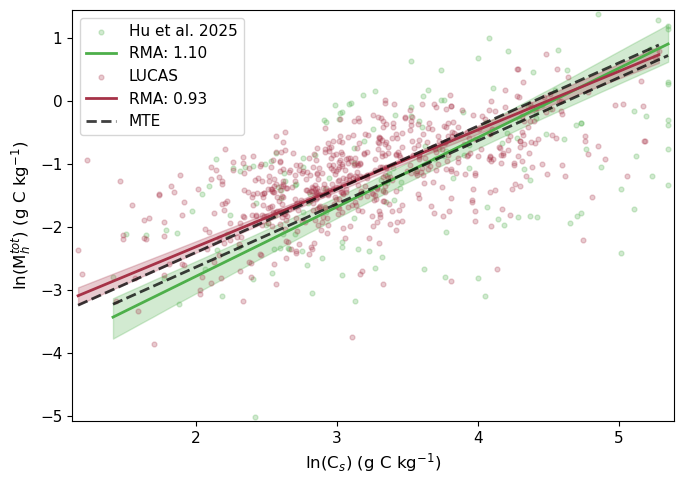

In [8]:
### MBC vs SOC

# He et al. 2026
x_he = ma.log(soc_he)
y_he = ma.log(mbc_he)

# LUCAS
x_lucas = ma.log(soc_lucas)
y_lucas = ma.log(mbc_lucas)

res_he = rma_regression_with_bootstrap(x_he, y_he, n_boot=N_BOOT, ci=CI_LEVEL, random_state=SEED)
res_lucas = rma_regression_with_bootstrap(x_lucas, y_lucas, n_boot=N_BOOT, ci=CI_LEVEL, random_state=SEED)

test_he = bootstrap_slope_test(res_he, null_slope=1.0)
test_lucas = bootstrap_slope_test(res_lucas, null_slope=1.0)

print(f"Hu et al. 2025: slope = {res_he['slope']:.2f} (95% CI: {res_he['slope_ci'][0]:.2f}-{res_he['slope_ci'][1]:.2f}), p = {test_he['p_value']:.4f}", 'n points (Hu et al. 2025):', res_he["n_valid"])
print(f"LUCAS: slope = {res_lucas['slope']:.2f} (95% CI: {res_lucas['slope_ci'][0]:.2f}-{res_lucas['slope_ci'][1]:.2f}), p = {test_lucas['p_value']:.4f}", 'n points (LUCAS):', res_lucas["n_valid"])
      
fig, ax = plt.subplots(figsize=(7, 5))
def plot_dataset(ax, res, color, label):
    ax.scatter(res['x_valid'], res['y_valid'], s=12, alpha=0.25, color=color,
               label=f'{label}')

    xline = np.linspace(res['x_valid'].min(), res['x_valid'].max(), 200)
    boot_lines = res['boot_slopes'][:, None] * xline[None, :] + res['boot_intercepts'][:, None]
    lo = (100.0 - res['ci']) / 2.0
    hi = 100.0 - lo
    band_lower = np.nanpercentile(boot_lines, lo, axis=0)
    band_upper = np.nanpercentile(boot_lines, hi, axis=0)
    ax.fill_between(xline, band_lower, band_upper, color=color, alpha=0.25)

    yline = res['slope'] * xline + res['intercept']
    ax.plot(xline, yline, color=color, lw=2,
            label=f'RMA: {res["slope"]:.2f}')

    xm, ym = res['x_valid'].mean(), res['y_valid'].mean()
    intercept_mte = ym - 1.0 * xm
    yline_mte = 1.0 * xline + intercept_mte
    ax.plot(xline, yline_mte, color='k', linestyle='--', lw=2, alpha=0.75)

    return xline, np.concatenate([res['y_valid'], yline, yline_mte, band_lower, band_upper])

xl1, yv1 = plot_dataset(ax, res_he, '#4DAF4A', 'Hu et al. 2025')
xl2, yv2 = plot_dataset(ax, res_lucas, '#A63247', 'LUCAS')
ax.plot([], [], color='k', linestyle='--', lw=2, label='MTE', alpha=0.75)

x_all = np.concatenate([xl1, xl2])
y_all = np.concatenate([yv1, yv2])
xpad = 0.01 * (x_all.max() - x_all.min())
ypad = 0.01 * (y_all.max() - y_all.min())
ax.set_xlim(x_all.min() - xpad, x_all.max() + xpad)
ax.set_ylim(y_all.min() - ypad, y_all.max() + ypad)

ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))

ax.set_xlabel(r'ln(C$_{s}$) (g C kg$^{-1}$)')
ax.set_ylabel(r'ln(M$_{h}^{tot}$) (g C kg$^{-1}$)')
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR/'Figure_4.pdf', bbox_inches='tight')  
plt.show()

Hu et al. 2025: slope = 1.11 (95% CI: 1.04-1.19), p = 0.0032 n points (Hu et al. 2025): 237
Cruz-Paredes et al. 2023: slope = 0.94 (95% CI: 0.84-1.07), p = 0.3702 n points (Cruz-Paredes et al. 2023): 54


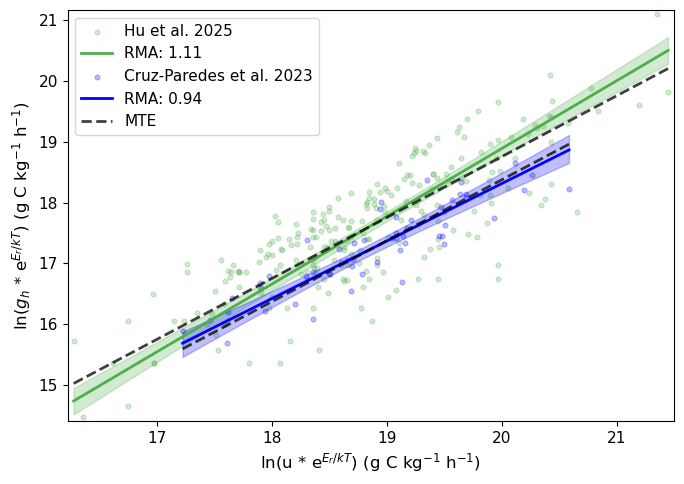

In [9]:
### Uptake vs Growth

# He et al. 2026
x_he = ma.log(uptake_T_he)
y_he = ma.log(growth_T_he)

# Barangari
x_brangari = ma.log(uptake_T_brangari)
y_brangari = ma.log(growth_T_brangari)

res_he = rma_regression_with_bootstrap(x_he, y_he, n_boot=N_BOOT, ci=CI_LEVEL, random_state=SEED)
res_brangari = rma_regression_with_bootstrap(x_brangari, y_brangari, n_boot=N_BOOT, ci=CI_LEVEL, random_state=SEED)

test_he = bootstrap_slope_test(res_he, null_slope=1.0)
test_brangari = bootstrap_slope_test(res_brangari, null_slope=1.0)

print(f"Hu et al. 2025: slope = {res_he['slope']:.2f} (95% CI: {res_he['slope_ci'][0]:.2f}-{res_he['slope_ci'][1]:.2f}), p = {test_he['p_value']:.4f}", 'n points (Hu et al. 2025):', res_he["n_valid"])
print(f"Cruz-Paredes et al. 2023: slope = {res_brangari['slope']:.2f} (95% CI: {res_brangari['slope_ci'][0]:.2f}-{res_brangari['slope_ci'][1]:.2f}), p = {test_brangari['p_value']:.4f}", 'n points (Cruz-Paredes et al. 2023):', res_brangari["n_valid"])

fig, ax = plt.subplots(figsize=(7, 5))
def plot_dataset(ax, res, color, label):
    ax.scatter(res['x_valid'], res['y_valid'], s=12, alpha=0.25, color=color,
               label=f'{label}')

    xline = np.linspace(res['x_valid'].min(), res['x_valid'].max(), 200)
    boot_lines = res['boot_slopes'][:, None] * xline[None, :] + res['boot_intercepts'][:, None]
    lo = (100.0 - res['ci']) / 2.0
    hi = 100.0 - lo
    band_lower = np.nanpercentile(boot_lines, lo, axis=0)
    band_upper = np.nanpercentile(boot_lines, hi, axis=0)
    ax.fill_between(xline, band_lower, band_upper, color=color, alpha=0.25)

    yline = res['slope'] * xline + res['intercept']
    ax.plot(xline, yline, color=color, lw=2,
            label=f'RMA: {res["slope"]:.2f}')

    xm, ym = res['x_valid'].mean(), res['y_valid'].mean()
    intercept_mte = ym - 1.0 * xm
    yline_mte = 1.0 * xline + intercept_mte
    ax.plot(xline, yline_mte, color='k', linestyle='--', lw=2, alpha=0.75)

    return xline, np.concatenate([res['y_valid'], yline, yline_mte, band_lower, band_upper])

xl1, yv1 = plot_dataset(ax, res_he, '#4DAF4A', 'Hu et al. 2025')
xl2, yv2 = plot_dataset(ax, res_brangari, 'blue', 'Cruz-Paredes et al. 2023')
ax.plot([], [], color='k', linestyle='--', lw=2, label='MTE', alpha=0.75)

x_all = np.concatenate([xl1, xl2])
y_all = np.concatenate([yv1, yv2])
xpad = 0.01 * (x_all.max() - x_all.min())
ypad = 0.01 * (y_all.max() - y_all.min())
ax.set_xlim(x_all.min() - xpad, x_all.max() + xpad)
ax.set_ylim(y_all.min() - ypad, y_all.max() + ypad)

ax.set_xlabel(r'ln(u * e$^{E_{r}/kT}$) (g C kg$^{-1}$ h$^{-1}$)')
ax.set_ylabel(r'ln($g_{h}$ * e$^{E_{r}/kT}$) (g C kg$^{-1}$ h$^{-1}$)')
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR/'Figure_3.pdf', bbox_inches='tight')
plt.show()

Hu et al. 2025: slope = 1.18 (95% CI: 1.06-1.31), p = 0.0016 n points (Hu et al. 2025): 234
Cruz-Paredes et al. 2023: slope = 1.14 (95% CI: 0.96-1.37), p = 0.1400 n points (Cruz-Paredes et al. 2023): 54


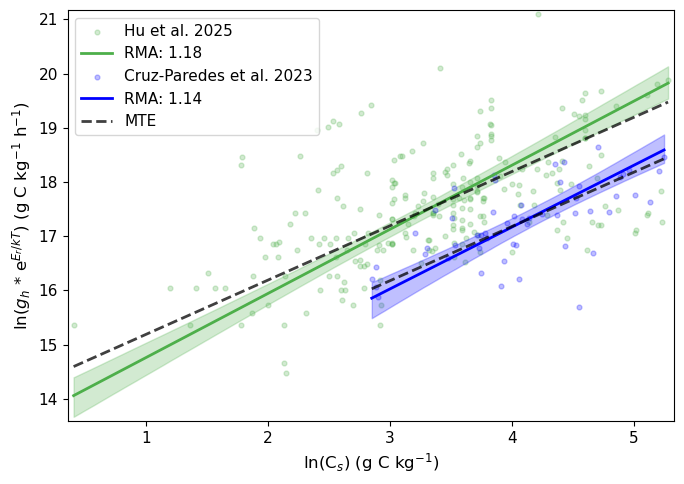

In [10]:
### SOC vs Growth

# He et al. 2026
x_he = ma.log(soc_he)
y_he = ma.log(growth_T_he)

# Barangari
x_brangari = ma.log(soc_brangari)
y_brangari = ma.log(growth_T_brangari)

res_he = rma_regression_with_bootstrap(x_he, y_he, n_boot=N_BOOT, ci=CI_LEVEL, random_state=SEED)
res_brangari = rma_regression_with_bootstrap(x_brangari, y_brangari, n_boot=N_BOOT, ci=CI_LEVEL, random_state=SEED)

test_he = bootstrap_slope_test(res_he, null_slope=1.0)
test_brangari = bootstrap_slope_test(res_brangari, null_slope=1.0)

print(f"Hu et al. 2025: slope = {res_he['slope']:.2f} (95% CI: {res_he['slope_ci'][0]:.2f}-{res_he['slope_ci'][1]:.2f}), p = {test_he['p_value']:.4f}", 'n points (Hu et al. 2025):', res_he["n_valid"])
print(f"Cruz-Paredes et al. 2023: slope = {res_brangari['slope']:.2f} (95% CI: {res_brangari['slope_ci'][0]:.2f}-{res_brangari['slope_ci'][1]:.2f}), p = {test_brangari['p_value']:.4f}", 'n points (Cruz-Paredes et al. 2023):', res_brangari["n_valid"])

fig, ax = plt.subplots(figsize=(7, 5))
def plot_dataset(ax, res, color, label):
    ax.scatter(res['x_valid'], res['y_valid'], s=12, alpha=0.25, color=color,
               label=f'{label}')

    xline = np.linspace(res['x_valid'].min(), res['x_valid'].max(), 200)
    boot_lines = res['boot_slopes'][:, None] * xline[None, :] + res['boot_intercepts'][:, None]
    lo = (100.0 - res['ci']) / 2.0
    hi = 100.0 - lo
    band_lower = np.nanpercentile(boot_lines, lo, axis=0)
    band_upper = np.nanpercentile(boot_lines, hi, axis=0)
    ax.fill_between(xline, band_lower, band_upper, color=color, alpha=0.25)

    yline = res['slope'] * xline + res['intercept']
    ax.plot(xline, yline, color=color, lw=2,
            label=f'RMA: {res["slope"]:.2f}')

    xm, ym = res['x_valid'].mean(), res['y_valid'].mean()
    intercept_mte = ym - 1.0 * xm
    yline_mte = 1.0 * xline + intercept_mte
    ax.plot(xline, yline_mte, color='k', linestyle='--', lw=2, alpha=0.75)

    return xline, np.concatenate([res['y_valid'], yline, yline_mte, band_lower, band_upper])

xl1, yv1 = plot_dataset(ax, res_he, '#4DAF4A', 'Hu et al. 2025')
xl2, yv2 = plot_dataset(ax, res_brangari, 'blue', 'Cruz-Paredes et al. 2023')
ax.plot([], [], color='k', linestyle='--', lw=2, label='MTE', alpha=0.75)

x_all = np.concatenate([xl1, xl2])
y_all = np.concatenate([yv1, yv2])
xpad = 0.01 * (x_all.max() - x_all.min())
ypad = 0.01 * (y_all.max() - y_all.min())
ax.set_xlim(x_all.min() - xpad, x_all.max() + xpad)
ax.set_ylim(y_all.min() - ypad, y_all.max() + ypad)

ax.set_xlabel(r'ln(C$_{s}$) (g C kg$^{-1}$)')
ax.set_ylabel(r'ln($g_{h}$ * e$^{E_{r}/kT}$) (g C kg$^{-1}$ h$^{-1}$)')
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR/'FigS1.png', dpi=300, bbox_inches='tight')
plt.show()

c:\Users\reva4589\AppData\Local\anaconda3\envs\python_beck\Lib\site-packages\numpy\ma\core.py:994: RuntimeWarning: overflow encountered in exp
  result = self.f(d, *args, **kwargs)


Hu et al. 2025 slopes: 0.9938204505798393 1.0516584469327028
LUCAS slopes: 1.1450712317488785 1.1450712317488787


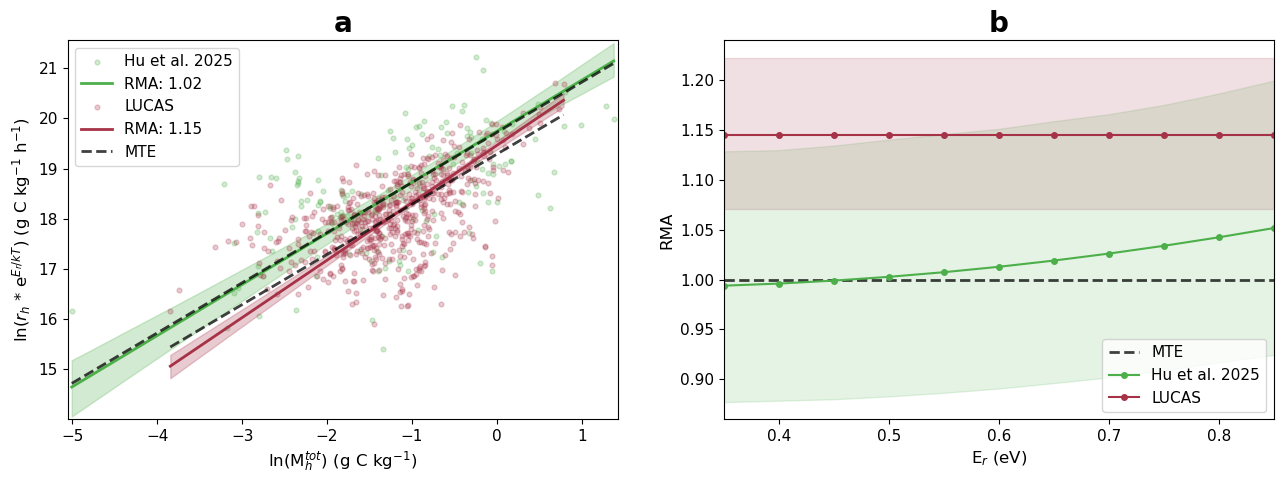

In [11]:
### Combined figure: (a) MBC vs Rh scaling, (b) sensitivity to Er

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax1, ax2 = axes

# ============ Panel (a): MBC vs Rh ============

# He et al. 2026
x_he = ma.log(mbc_he)
y_he = ma.log(rh_T_he)

# LUCAS
x_lucas = ma.log(mbc_lucas)
y_lucas = ma.log(rh_T_lucas)

res_he = rma_regression_with_bootstrap(x_he, y_he, n_boot=N_BOOT, ci=CI_LEVEL, random_state=SEED)
res_lucas = rma_regression_with_bootstrap(x_lucas, y_lucas, n_boot=N_BOOT, ci=CI_LEVEL, random_state=SEED)

test_he = bootstrap_slope_test(res_he, null_slope=1.0)
test_lucas = bootstrap_slope_test(res_lucas, null_slope=1.0)

def plot_dataset(ax, res, color, label):
    ax.scatter(res['x_valid'], res['y_valid'], s=12, alpha=0.25, color=color, label=f'{label}')

    xline = np.linspace(res['x_valid'].min(), res['x_valid'].max(), 200)
    boot_lines = res['boot_slopes'][:, None] * xline[None, :] + res['boot_intercepts'][:, None]
    lo = (100.0 - res['ci']) / 2.0
    hi = 100.0 - lo
    band_lower = np.nanpercentile(boot_lines, lo, axis=0)
    band_upper = np.nanpercentile(boot_lines, hi, axis=0)
    ax.fill_between(xline, band_lower, band_upper, color=color, alpha=0.25)

    yline = res['slope'] * xline + res['intercept']
    ax.plot(xline, yline, color=color, lw=2, label=f'RMA: {res["slope"]:.2f}')

    xm, ym = res['x_valid'].mean(), res['y_valid'].mean()
    intercept_mte = ym - 1.0 * xm
    yline_mte = 1.0 * xline + intercept_mte
    ax.plot(xline, yline_mte, color='k', linestyle='--', lw=2, alpha=0.75)

    return xline, np.concatenate([res['y_valid'], yline, yline_mte, band_lower, band_upper])

xl1, yv1 = plot_dataset(ax1, res_he, '#4DAF4A', 'Hu et al. 2025')
xl2, yv2 = plot_dataset(ax1, res_lucas, '#A63247', 'LUCAS')
ax1.plot([], [], color='k', linestyle='--', lw=2, label='MTE', alpha=0.75)

x_all = np.concatenate([xl1, xl2])
y_all = np.concatenate([yv1, yv2])
xpad = 0.0075 * (x_all.max() - x_all.min())
ypad = 0.0075 * (y_all.max() - y_all.min())
ax1.set_xlim(x_all.min() - xpad, x_all.max() + xpad)
ax1.set_ylim(y_all.min() - ypad, y_all.max() + ypad)

ax1.set_xlabel(r'ln(M$_{h}^{tot}$) (g C kg$^{-1}$)')
ax1.set_ylabel(r'ln($r_{h}$ * e$^{E_{r}/kT}$) (g C kg$^{-1}$ h$^{-1}$)')
ax1.legend()
ax1.set_title('a', fontweight='bold', fontsize=20)

# ============ Panel (b): sensitivity to Er ============

param_values = np.linspace(0.35, 0.85, 11)   # Er values

# He et al. 2026
x_he = ma.log(mbc_he)
y_he_raw = rh_he.copy()
# LUCAS
x_lucas = ma.log(mbc_lucas)
y_lucas_raw = rh_lucas.copy()

ax2.axhline(1.0, color='k', linestyle='--', lw=2, alpha=0.75, label='MTE')

slopes_he, lo_he, hi_he = run_sensitivity(x_he, y_he_raw, incT_he, parameters=param_values)
slopes_lucas, lo_lucas, hi_lucas = run_sensitivity(x_lucas, y_lucas_raw, 293.15, parameters=param_values)

print('Hu et al. 2025 slopes:', np.min(slopes_he), np.max(slopes_he))
print('LUCAS slopes:', np.min(slopes_lucas), np.max(slopes_lucas))

ax2.plot(param_values, slopes_he, color='#4DAF4A', marker='o', markersize=4, lw=1.5, label='Hu et al. 2025')
ax2.fill_between(param_values, lo_he, hi_he, color='#4DAF4A', alpha=0.15)
ax2.plot(param_values, slopes_lucas, color='#A63247', marker='o', markersize=4, lw=1.5, label='LUCAS')
ax2.fill_between(param_values, lo_lucas, hi_lucas, color='#A63247', alpha=0.15)

ax2.set_xlabel(r'E$_r$ (eV)')
ax2.set_ylabel('RMA')
ax2.set_xlim(param_values.min(), param_values.max())
ax2.legend(loc='lower right')
ax2.set_title('b', fontweight='bold', fontsize=20)

plt.tight_layout(w_pad=2.5)
plt.savefig(FIG_DIR/'Figure_2.pdf', bbox_inches='tight')  
plt.show()